In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
import warnings

warnings.filterwarnings(
    "ignore",
    message="KMeans is known to have a memory leak on Windows with MKL"
)

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.datasets import load_iris
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler


In [3]:
iris = load_iris()
X = iris.data

df = pd.DataFrame(X, columns=iris.feature_names)


In [4]:
print("\nDataset shape:")
print(df.shape)

print("\nMissing values:")
print(df.isnull().sum())


Dataset shape:
(150, 4)

Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64


In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [6]:
inertia = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)


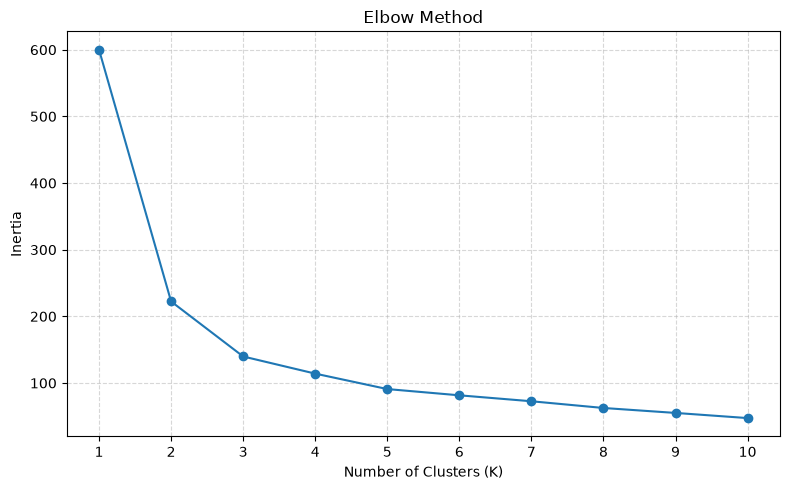

In [7]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(range(1, 11))
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [8]:
silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

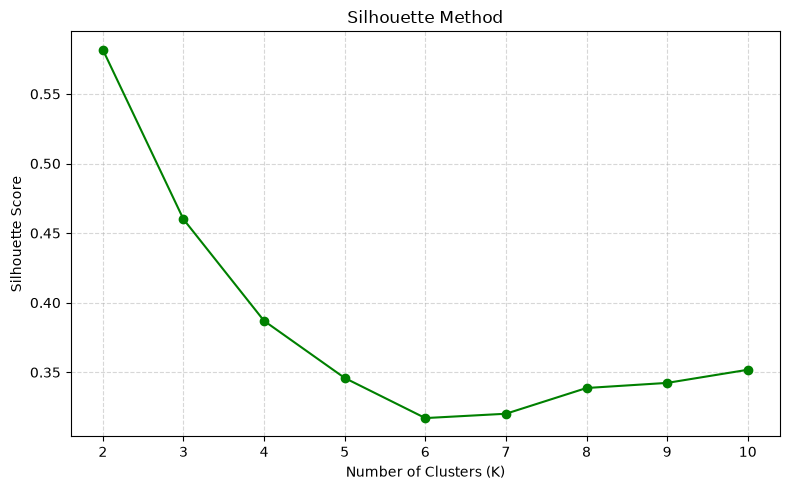

In [9]:
plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), silhouette_scores, marker="o", color="green")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Method")
plt.xticks(range(2, 11))
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


In [10]:
optimal_k = 3

kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

In [11]:
df["Cluster"] = clusters

print("\nClustered Data Preview:")
display(df.head(10))



Clustered Data Preview:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Cluster
0,5.1,3.5,1.4,0.2,1
1,4.9,3.0,1.4,0.2,1
2,4.7,3.2,1.3,0.2,1
3,4.6,3.1,1.5,0.2,1
4,5.0,3.6,1.4,0.2,1
5,5.4,3.9,1.7,0.4,1
6,4.6,3.4,1.4,0.3,1
7,5.0,3.4,1.5,0.2,1
8,4.4,2.9,1.4,0.2,1
9,4.9,3.1,1.5,0.1,1


In [13]:
# ------------------------------------------
# 11. FINAL SILHOUETTE SCORE
# ------------------------------------------
final_score = silhouette_score(X_scaled, clusters)
print(f"\nFinal Silhouette Score (k={optimal_k}): {final_score:.4f}")


Final Silhouette Score (k=3): 0.4599


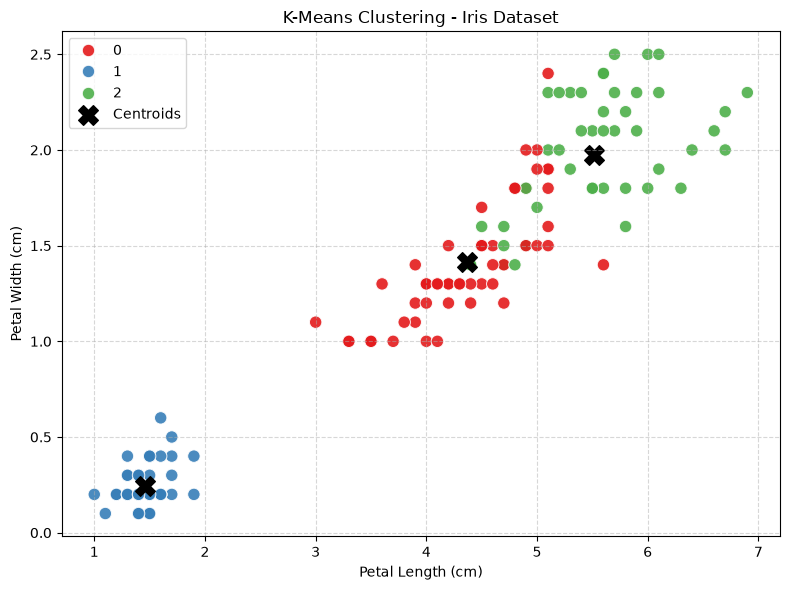

In [14]:
# ------------------------------------------
# 12. VISUALIZE CLUSTERS
# ------------------------------------------
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df,
    x="petal length (cm)",
    y="petal width (cm)",
    hue="Cluster",
    palette="Set1",
    s=80,
    alpha=0.9,
)

# Plot unscaled cluster centers on top of original feature coordinates
centers_original = scaler.inverse_transform(kmeans.cluster_centers_)
petal_length_idx = iris.feature_names.index("petal length (cm)")
petal_width_idx = iris.feature_names.index("petal width (cm)")

plt.scatter(
    centers_original[:, petal_length_idx],
    centers_original[:, petal_width_idx],
    marker="X",
    s=200,
    c="black",
    label="Centroids",
)

plt.title("K-Means Clustering - Iris Dataset")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [15]:
# ------------------------------------------
# 13. DISPLAY CLUSTER CENTERS
# ------------------------------------------
centers_df = pd.DataFrame(centers_original, columns=iris.feature_names)

print("\nCluster Centers (Original Feature Scale):")
display(centers_df.round(4))


Cluster Centers (Original Feature Scale):


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.8019,2.6736,4.3698,1.4132
1,5.0060,3.4280,1.4620,0.2460
2,6.7809,3.0957,5.5106,1.9723
